In [2]:
# Imports (PyTorch Geometric GraphSAGE)
import pandas as pd
import numpy as np
from torch_geometric.data import Data
from torch_geometric.nn import SAGEConv
import torch.nn.functional as F
import torch

In [3]:
# Load the mutual-kNN edge list (SPECTER graph)
mut_edgs = np.load(r"kg/mutual_edges@20.npy")
mut_edgs.shape

(516583, 2)

In [4]:
# Inspect edges
mut_edgs

array([[ 41467,  42590],
       [ 25256, 102841],
       [ 26172, 110231],
       ...,
       [136261, 146600],
       [ 60066,  65545],
       [ 60902, 143125]], shape=(516583, 2))

In [5]:
# Load SPECTER embeddings
embd = pd.read_csv(r"data/specter_embeddings.csv").drop(columns=['original_id_clean'])  
embd.head()

,project_id,specter_embedding_0,specter_embedding_1,specter_embedding_2,specter_embedding_3,specter_embedding_4,specter_embedding_5,specter_embedding_6,specter_embedding_7,specter_embedding_8,...,specter_embedding_758,specter_embedding_759,specter_embedding_760,specter_embedding_761,specter_embedding_762,specter_embedding_763,specter_embedding_764,specter_embedding_765,specter_embedding_766,specter_embedding_767
0,0,-0.362291,1.048671,0.595254,-0.452969,0.130679,-0.753185,-0.559871,0.633012,0.544979,...,0.073975,-1.110611,0.944754,0.682057,0.666358,-0.090816,-0.156717,0.244948,0.692705,0.590688
1,2,-0.439786,0.765530,0.333816,-0.228252,0.821623,-0.042048,0.395873,0.196598,0.516431,...,0.007341,-1.544107,1.061482,0.893701,0.390635,0.195787,0.161993,-0.035524,1.541261,1.091505
2,3,-0.009004,0.396810,0.429890,-0.111672,0.422623,-0.328100,-0.175239,1.196574,0.450798,...,-0.286731,-1.943584,0.421188,1.321711,-0.241398,-0.169670,0.614148,-0.250611,1.043618,1.471813
3,5,0.019991,0.770271,-0.205909,-0.361313,-0.160810,-0.339320,0.291656,0.741180,0.223188,...,0.255495,-1.617394,0.652282,0.675482,-0.270218,-0.458816,0.000720,-0.049819,1.302014,-0.347194
4,6,0.165885,0.157862,0.430685,0.589608,0.827854,-0.669882,0.357143,0.577054,0.712081,...,-0.308747,-1.909491,0.734672,0.635045,-0.447741,-0.159738,0.051587,0.188710,0.718381,1.436688


In [6]:
# Split into project ids and the embedding matrix
proj_ids = embd["project_id"].astype(str).values
embeddings = embd.drop(columns=['project_id']).values

In [7]:
# Build id <-> row-index maps
id2idx = {pid: idx for idx, pid in enumerate(proj_ids)}
idx2id = {i:pid for pid,i in id2idx.items()}
len(id2idx)

131772

In [8]:
# Embeddings as a float tensor (node features)
X = torch.tensor(
    embeddings, dtype=torch.float

)
X.shape

torch.Size([131772, 768])

In [9]:
# Map edge project_ids to row indices; count any unmapped
mapped_edges = []
missing=0
for a,b in mut_edgs:
    a=str(a)
    b=str(b)
    if a in id2idx and b in id2idx:
        mapped_edges.append([id2idx[a], id2idx[b]])
    else:
        missing+=1
mapped_edges = np.array(mapped_edges)
mapped_edges.shape, missing

((516583, 2), 0)

In [10]:
# Build an undirected edge_index tensor
edge_index=torch.tensor(mapped_edges, dtype=torch.long).t()
edge_index = torch.cat([edge_index, edge_index.flip(0)], dim=1)  # Make it undirected
edge_index.shape

torch.Size([2, 1033166])

In [11]:
# Inspect edge_index
edge_index

tensor([[ 35433,  20964,  21841,  ..., 128420,  56723, 125294],
        [ 36533,  89020,  95709,  ..., 119098,  52363,  53153]])

In [12]:
# Node count
num_nodes = X.size(0)
num_nodes

131772

In [13]:
# X=torch.nn.functional.normalize(X, p=2, dim=1)

In [14]:
# PyG graph object
data = Data(X, edge_index=edge_index,num_nodes=num_nodes)
data

Data(x=[131772, 768], edge_index=[2, 1033166], num_nodes=131772)

In [15]:
# 2-layer GraphSAGE encoder (768 -> 256 -> 768)
torch.manual_seed(42)
class GraphSAGE(torch.nn.Module):
    def __init__(self,in_dim,hid_dim):
        super(GraphSAGE, self).__init__()
        self.conv1 = SAGEConv(in_dim, hid_dim,aggr='mean')
        self.conv2 = SAGEConv(hid_dim, in_dim,aggr='mean')
    def forward(self, x, edge_index):
        x = self.conv1(x, edge_index)
        x = F.relu(x)
        x = self.conv2(x, edge_index)
        return x

In [16]:
# Instantiate the model
model = GraphSAGE(in_dim=768, hid_dim=256)
print(model)

GraphSAGE(
  (conv1): SAGEConv(768, 256, aggr=mean)
  (conv2): SAGEConv(256, 768, aggr=mean)
)


In [17]:
# Adam optimizer
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

In [18]:
# Contrastive loss (simple version; superseded by the chunked one below)
def contrastive_loss(x, edge_index, num_nodes,margin=0.5):
    u, v = edge_index
    sim = F.cosine_similarity(x[u], x[v])
    neg_v = torch.randint(0, num_nodes, (u.size(0),), device=x.device)
    neg_sim = F.cosine_similarity(x[u], x[neg_v]) 
    loss = F.relu(margin-sim+neg_sim)
    return loss.mean()

In [19]:
# Contrastive loss (edge-sampled + chunked; this is the one used for training)
def contrastive_loss(x, edge_index, num_nodes, margin=0.5, max_pos_edges=200_000, chunk_size=20_000):
    # x should be L2-normalized: cosine(x_i, x_j) == dot(x_i, x_j)
    E = edge_index.size(1)

    # Sample positive edges if too many (prevents huge gathers)
    if E > max_pos_edges:
        idx = torch.randint(0, E, (max_pos_edges,), device=edge_index.device)
        edge_index = edge_index[:, idx]
        E = max_pos_edges

    u_all = edge_index[0]
    v_all = edge_index[1]

    total = x.new_zeros(())
    count = 0

    for start in range(0, E, chunk_size):
        end = min(E, start + chunk_size)
        u = u_all[start:end]
        v = v_all[start:end]

        x_u = x[u]                       # (chunk, d)
        pos = (x_u * x[v]).sum(dim=1)    # cosine since normalized

        neg_v = torch.randint(0, num_nodes, (u.numel(),), device=x.device)
        neg = (x_u * x[neg_v]).sum(dim=1)

        loss = torch.relu(margin - pos + neg)
        total += loss.sum()
        count += loss.numel()

    return total / max(count, 1)

In [20]:
# Train GraphSAGE with the contrastive loss
losses=[]
epochs = 15
for epoch in range(1, epochs + 1):
    model.train()
    optimizer.zero_grad()
    out = model(data.x, data.edge_index)
    out_norm = F.normalize(out, dim=1)
    # loss = contrastive_loss(out_norm, data.edge_index, data.num_nodes)  
    pos_edge_index = data.edge_index[:, : data.edge_index.size(1)//2]
    loss = contrastive_loss(out_norm, pos_edge_index, data.num_nodes,
                        margin=0.5, max_pos_edges=200_000, chunk_size=20_000)
    loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    optimizer.step()
    print(f'Epoch {epoch}, Loss: {loss.item()}')
    losses.append(loss.item())

Epoch 1, Loss: 0.3093026280403137
Epoch 2, Loss: 0.4931710660457611
Epoch 3, Loss: 0.4890115261077881
Epoch 4, Loss: 0.47781071066856384
Epoch 5, Loss: 0.4527535140514374
Epoch 6, Loss: 0.4171210527420044
Epoch 7, Loss: 0.38267844915390015
Epoch 8, Loss: 0.2980111539363861
Epoch 9, Loss: 0.21180488169193268
Epoch 10, Loss: 0.1955033838748932
Epoch 11, Loss: 0.19909349083900452
Epoch 12, Loss: 0.19454458355903625
Epoch 13, Loss: 0.18095985054969788
Epoch 14, Loss: 0.16967159509658813
Epoch 15, Loss: 0.15990404784679413


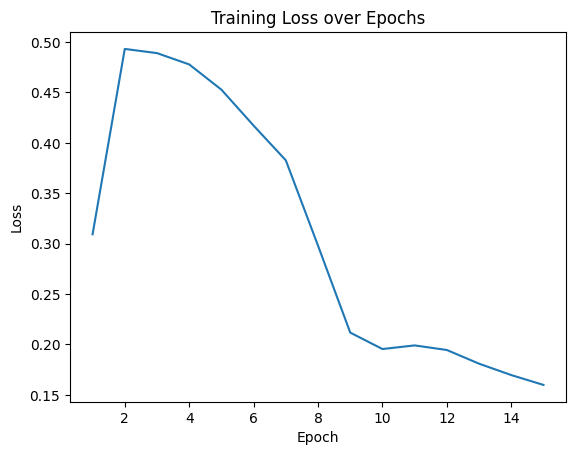

In [21]:
# Plot training loss
import matplotlib.pyplot as plt
plt.plot(range(1, epochs + 1), losses)
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training Loss over Epochs')
plt.show()

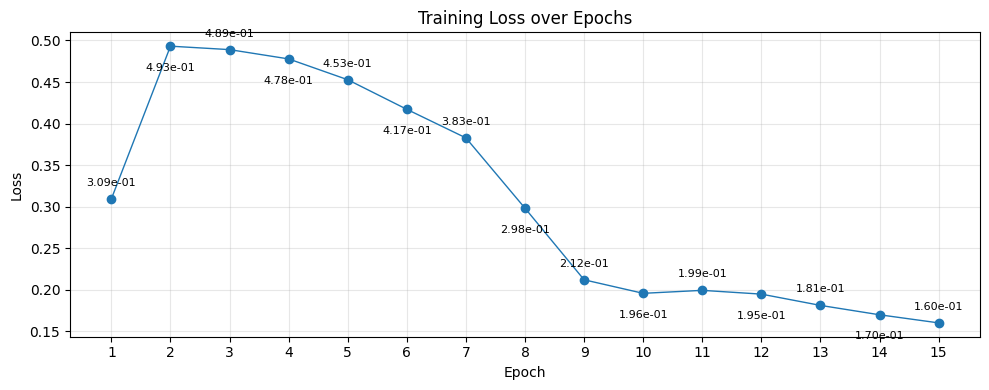

In [29]:
# Plot training loss with per-epoch value annotations
xs = list(range(1, epochs + 1))

plt.figure(figsize=(10, 4))
plt.plot(xs, losses, marker="o", linewidth=1)
plt.xticks(xs)

for i, (x, y) in enumerate(zip(xs, losses)):
    dy = 8 if i % 2 == 0 else -12
    va = "bottom" if i % 2 == 0 else "top"
    plt.annotate(
    f"{y:.2e}",   # <-- 3.09e-14 style
    (x, y),
    textcoords="offset points",
    xytext=(0, dy),
    ha="center",
    va=va,
    fontsize=8,
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training Loss over Epochs")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [23]:
# Encode final node embeddings (eval mode)
model.eval()
with torch.no_grad():
    z = model(data.x, data.edge_index)

In [24]:
# To numpy
emb_np = z.numpy()

In [25]:
# Assemble embeddings DataFrame keyed by project_id
final_df = pd.DataFrame(
    emb_np,
    columns = [f"emb_{i+1}" for i in range(emb_np.shape[1])]
)
final_df.insert(0, 'project_id', pd.Series(idx2id,dtype='int64'))

In [26]:
# Inspect
final_df

,project_id,emb_1,emb_2,emb_3,emb_4,emb_5,emb_6,emb_7,emb_8,emb_9,...,emb_759,emb_760,emb_761,emb_762,emb_763,emb_764,emb_765,emb_766,emb_767,emb_768
0,0,78.046448,34.785656,46.533138,87.304070,108.159485,-38.565559,-96.111099,-19.484253,-107.343536,...,104.813332,-113.439644,2.102797,44.168964,10.207823,-65.081390,23.592239,-28.720625,-19.220865,-11.495221
1,2,45.436035,-14.557889,-4.197924,39.633461,54.004219,-7.191236,-33.035145,-0.921150,-51.179344,...,64.618637,-36.283482,-0.548837,7.424758,-28.144764,-32.720531,-21.017029,-9.348602,-9.454002,-14.708620
2,3,66.991638,39.996185,31.451254,77.882698,95.675415,-9.749729,-82.960052,-15.268078,-106.092392,...,96.548927,-88.024971,5.291243,51.931068,-36.722321,-57.557411,-3.284580,-31.380337,-16.685978,-9.652761
3,5,59.070770,-26.687449,-8.575197,65.295616,100.394043,-30.876492,-108.039391,-21.445972,-121.077980,...,132.236923,-109.526993,-29.672632,9.578777,-59.332729,-62.465443,-48.564758,-12.879054,-4.833248,-6.201952
4,6,66.691360,50.533962,42.165291,76.712128,86.333481,-10.484695,-70.626686,-12.466942,-88.288620,...,75.506279,-77.406998,10.405765,53.757092,-15.377699,-54.984337,14.065369,-26.168821,-19.139481,-13.691978
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
131767,150101,191.293457,247.534363,283.713867,239.546249,250.763916,-56.823071,-249.482376,-1.219208,-263.802979,...,165.369736,-232.589874,127.741440,192.825317,162.335907,-86.530975,226.602997,-168.897522,-101.770325,21.534687
131768,150102,221.330139,303.198090,342.812531,279.586426,287.332275,-65.106926,-285.709534,-0.109776,-296.991638,...,177.974991,-266.974792,156.272263,229.393219,208.315872,-99.233795,281.724731,-195.978394,-121.905884,23.540594
131769,150103,202.139679,268.881134,305.479614,252.708405,259.240814,-59.710281,-256.187561,-2.860428,-267.364838,...,163.603653,-241.294128,136.566025,206.961578,183.775177,-91.613937,248.427856,-173.502823,-106.713783,18.534609
131770,150104,180.800812,233.489456,267.473572,226.679718,234.021255,-52.474869,-231.669205,-2.618645,-245.343689,...,153.664337,-215.482895,118.082222,182.348618,149.699951,-82.779289,212.474731,-158.618591,-93.236000,15.446232


In [27]:
# Sanity: row count matches and project_id is unique
print(final_df.shape[0]==len(idx2id),final_df['project_id'].is_unique)

True True


In [28]:
# Save GraphSAGE embeddings
final_df.to_csv(r"kg/project_graphsage_embeddings.csv", index=False)